In [50]:
# Core data libraries
import numpy as np # numerical operations / ədədi hesablamalar üçün
import pandas as pd # dataframes (for tables) / cədvəl tipli məlumat üçün əsas kitabxana

# Visualization libraries
import matplotlib.pyplot as plt  # basic plotting / sadə qrafiklər çəkmək
import seaborn as sns # advanced statistical plots / statistik vizuallaşdırma

# Machine learning tools from scikit-learn
from sklearn.model_selection import train_test_split # split data into train/test / məlumatı təlim və test hissələrinə bölmək
from sklearn.compose import ColumnTransformer # apply different transformers to columns / müxtəlif sütunlara fərqli çevrilmələr tətbiq etmək
from sklearn.impute import SimpleImputer # fill missing values / əskik dəyərləri doldurmaq
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# scaling, encoding

# Statistics and outlier detection tools
from scipy import stats # statistical functions / statistik funksiyalar (məsələn, z-score)


In [11]:

df = pd.read_csv("online_retail_sales.csv")
display(df.head(10))
print("Shape (rows, columns):", df.shape)
df.info() 
print("\nMissing values per column:")
display(df.isna().sum())


,order_id,customer_id,country,product_category,unit_price,quantity,discount,order_date,delivery_days
0,10001,2102,UK,Toys,92.35,7,25,2023-08-27,7
1,10002,2435,Netherlands,Books,118.63,1,10,2023-11-20,12
2,10003,2270,UK,Clothing,108.65,3,15,2023-10-23,12
3,10004,2106,Italy,Books,79.94,5,15,2023-07-06,12
4,10005,2071,UK,Toys,41.12,5,10,2023-07-27,11
5,10006,2020,Spain,Toys,34.25,6,20,2023-08-08,1
6,10007,2121,Spain,Home,99.21,1,30,2023-07-09,3
7,10008,2466,France,Clothing,106.18,1,10,2023-12-12,12
8,10009,2214,Germany,Toys,65.43,7,20,2023-10-11,11
9,10010,2330,Germany,Home,33.10,1,5,2023-12-18,4


Shape (rows, columns): (800, 9)
<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   order_id          800 non-null    int64  
 1   customer_id       800 non-null    int64  
 2   country           800 non-null    str    
 3   product_category  800 non-null    str    
 4   unit_price        800 non-null    float64
 5   quantity          800 non-null    int64  
 6   discount          800 non-null    int64  
 7   order_date        800 non-null    str    
 8   delivery_days     800 non-null    int64  
dtypes: float64(1), int64(5), str(3)
memory usage: 56.4 KB

Missing values per column:


order_id            0
customer_id         0
country             0
product_category    0
unit_price          0
quantity            0
discount            0
order_date          0
delivery_days       0
dtype: int64

In [16]:
duplicate_count = df['order_id'].duplicated().sum()
print(f"Number of duplicate order_id entries: {duplicate_count}")
print(duplicate_orders)
df = df.drop_duplicates()
invalid_discounts = df[(df['discount'] < 0) | (df['discount'] > 30)]
print(f"Invalid discount count: {len(invalid_discounts)}")

# Cap/clip values to the [0, 30] boundary
df['discount'] = df['discount'].clip(lower=0, upper=30)

invalid_qty = df[df['quantity'] <= 0]
invalid_price = df[df['unit_price'] <= 0]

print(f"Invalid quantity records: {len(invalid_qty)}")
print(f"Invalid unit price records: {len(invalid_price)}")

df = df[(df['quantity'] > 0) & (df['unit_price'] > 0)]

print(df.isnull().sum())

Number of duplicate order_id entries: 0
Empty DataFrame
Columns: [order_id, customer_id, country, product_category, unit_price, quantity, discount, order_date, delivery_days]
Index: []
Invalid discount count: 0
Invalid quantity records: 0
Invalid unit price records: 0
order_id            0
customer_id         0
country             0
product_category    0
unit_price          0
quantity            0
discount            0
order_date          0
delivery_days       0
dtype: int64


In [29]:
stats = df[['unit_price', 'quantity', 'delivery_days']].agg(['mean', 'median', 'std'])
print(stats)

min_delivery = df['delivery_days'].min()
max_delivery = df['delivery_days'].max()

print(f"Minimum delivery time: {min_delivery} days")
print(f"Maximum delivery time: {max_delivery} days")
print("\n")
avg_price_by_country = df.groupby('country')['unit_price'].mean().reset_index()
avg_price_by_country.columns = ['country', 'average_unit_price']

print(avg_price_by_country)
print("\n")
total_qty_by_category = df.groupby('product_category')['quantity'].sum().reset_index()
total_qty_by_category.columns = ['product_category', 'total_quantity_sold']

print(total_qty_by_category)

        unit_price  quantity  delivery_days
mean     63.761162   3.92375       7.355000
median   65.635000   4.00000       7.000000
std      33.493583   2.02622       4.053025
Minimum delivery time: 1 days
Maximum delivery time: 14 days


       country  average_unit_price
0       France           65.957438
1      Germany           58.455338
2        Italy           70.658506
3  Netherlands           64.769500
4        Spain           60.058119
5           UK           64.240288


  product_category  total_quantity_sold
0            Books                  644
1         Clothing                  625
2      Electronics                  585
3             Home                  565
4             Toys                  720


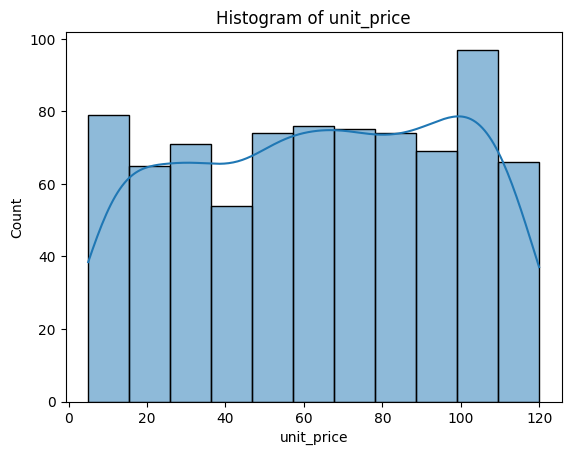

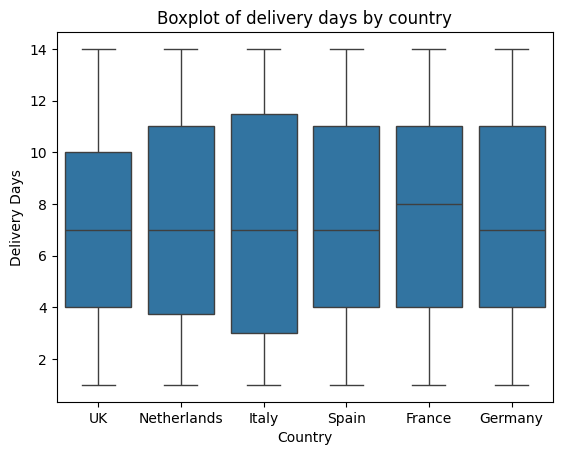

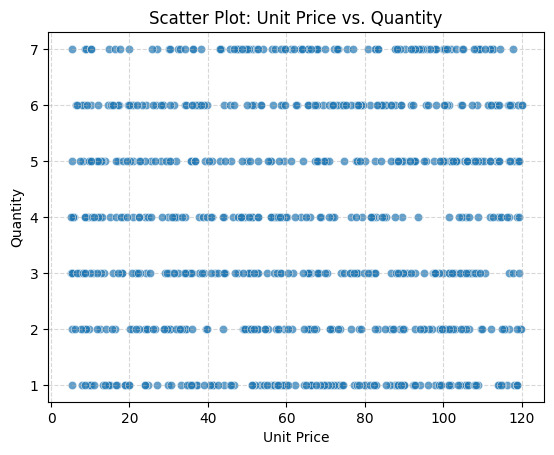

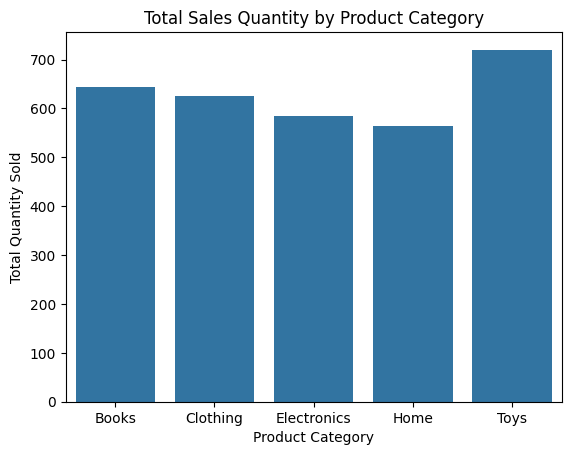

In [37]:
plt.figure()
plt.title(f"Histogram of unit_price")
plt.xlabel('unit_price')
if 'sns' in globals():  # check if seaborn is available
    sns.histplot(df['unit_price'].dropna(), kde=True)
else:
    plt.hist(df['unit_price'].dropna(), bins=20)
plt.show()


plt.figure()
plt.title("Boxplot of delivery days by country")

if 'sns' in globals():
    sns.boxplot(data=df, x='country', y='delivery_days')
    plt.xlabel("Country")
    plt.ylabel("Delivery Days")
else:
    df.boxplot(column='delivery_days', by='country')
    plt.title("Boxplot of Delivery Days by Country")
    plt.suptitle("")
    plt.xlabel("Country")
    plt.ylabel("Delivery Days")

plt.show()

plt.figure()
plt.title("Scatter Plot: Unit Price vs. Quantity")
plt.xlabel("Unit Price")
plt.ylabel("Quantity")

if 'sns' in globals():
    sns.scatterplot(data=df, x='unit_price', y='quantity', alpha=0.7)
else:
    plt.scatter(df['unit_price'], df['quantity'], alpha=0.7)

plt.grid(True, linestyle='--', alpha=0.5)
plt.show()


category_sales = df.groupby('product_category')['quantity'].sum().reset_index()

plt.figure()
plt.title("Total Sales Quantity by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Quantity Sold")

if 'sns' in globals():
    sns.barplot(data=category_sales, x='product_category', y='quantity')
else:
    plt.bar(category_sales['product_category'], category_sales['quantity'])

plt.show()

In [44]:
df['total_revenue'] = df['unit_price'] * df['quantity'] * (1 - df['discount'] / 100)

df['order_date'] = pd.to_datetime(df['order_date'])
df['order_month'] = df['order_date'].dt.month
df['fast_delivery'] = np.where(df['delivery_days'] <= 5, 1, 0)
encoder = OrdinalEncoder()
df['product_category_encoded'] = encoder.fit_transform(df[['product_category']])
display(df)

,order_id,customer_id,country,product_category,unit_price,quantity,discount,order_date,delivery_days,total_revenue,order_month,fast_delivery,product_category_encoded
0,10001,2102,UK,Toys,92.35,7,25,2023-08-27,7,484.8375,8,0,4.0
1,10002,2435,Netherlands,Books,118.63,1,10,2023-11-20,12,106.7670,11,0,0.0
2,10003,2270,UK,Clothing,108.65,3,15,2023-10-23,12,277.0575,10,0,1.0
3,10004,2106,Italy,Books,79.94,5,15,2023-07-06,12,339.7450,7,0,0.0
4,10005,2071,UK,Toys,41.12,5,10,2023-07-27,11,185.0400,7,0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,10796,2138,Italy,Books,35.92,2,20,2023-08-02,1,57.4720,8,1,0.0
796,10797,2510,Germany,Electronics,77.27,3,25,2023-05-31,5,173.8575,5,1,2.0
797,10798,2258,Germany,Toys,60.41,1,5,2023-10-02,2,57.3895,10,1,4.0
798,10799,2009,UK,Clothing,46.60,6,25,2023-12-04,14,209.7000,12,0,1.0


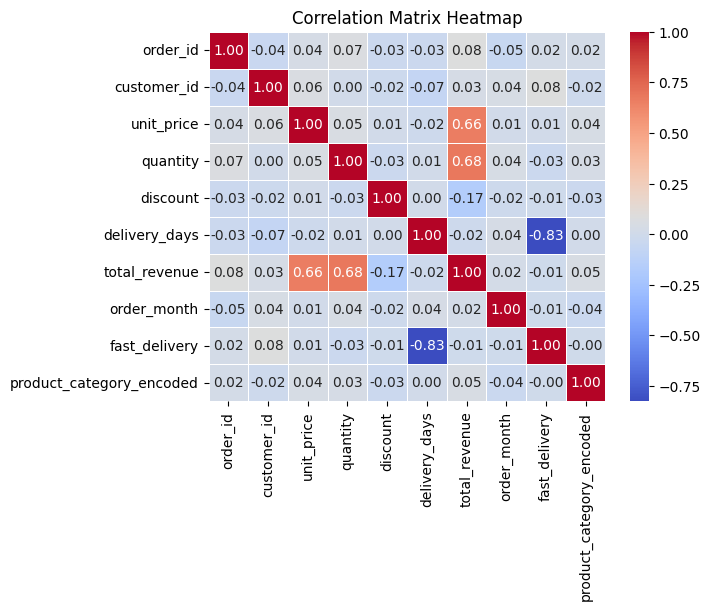

Top 2 features most correlated with total_revenue:
quantity      0.683984
unit_price    0.662452
Name: total_revenue, dtype: float64


In [47]:
num_df = df.select_dtypes(include=['number'])
corr_matrix = num_df.corr()
plt.figure()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix Heatmap")
plt.show()

top_2_features = (
    corr_matrix['total_revenue']
    .drop('total_revenue')
    .abs()            
    .nlargest(2)
)

print("Top 2 features most correlated with total_revenue:")
print(top_2_features)

In [59]:
y = df['total_revenue']
X = df.drop(
    columns=[
        'total_revenue',
        'order_date', 
        'order_id',
        'customer_id',
        'product_category',
        'country'
    ]
)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training features shape: {X_train.shape}")
print(f"Testing features shape: {X_test.shape}")

Training features shape: (640, 7)
Testing features shape: (160, 7)


In [60]:
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R² Score: {r2:.4f}")

Mean Absolute Error (MAE): 42.95
Mean Squared Error (MSE): 3406.33
R² Score: 0.8944
